### 📥 Step 1: Downloading the Driving Simulator Dataset
In this cell, we clone the simulator track dataset from GitHub. This downloads the camera images folder (`IMG/`) and the central tracking log file (`driving_log.csv`) directly into our workspace.

In [ ]:
#downloading data
!git clone https://github.com/rslim087a/track

Cloning into 'track'...
remote: Enumerating objects: 12163, done.
remote: Total 12163 (delta 0), reused 0 (delta 0), pack-reused 12163 (from 1)
Receiving objects: 100% (12163/12163), 156.98 MiB | 24.10 MiB/s, done.
Updating files: 100% (12160/12160), done.


### 📦 Step 2: Importing Libraries & Fixing Compatibility
Here, we install `imgaug` and import the key packages required for our deep learning pipeline (TensorFlow, OpenCV, Pandas, Matplotlib, and Scikit-learn). We also apply a compatibility patch so `imgaug` runs smoothly on modern NumPy versions.

In [ ]:
!pip install imgaug
import os
import numpy as np

# Patch NumPy 2.0 compatibility issue with imgaug
if not hasattr(np, "sctypes"):
    np.sctypes = {
        "int": [np.int8, np.int16, np.int32, np.int64],
        "uint": [np.uint8, np.uint16, np.uint32, np.uint64],
        "float": [np.float16, np.float32, np.float64],
        "others": [bool, complex]
    }

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Convolution2D, MaxPooling2D, Dropout, Flatten, Dense, Conv2D
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from imgaug import augmenters as iaa
import cv2
import pandas as pd
import ntpath
import random

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.0/948.0 kB 9.2 MB/s  0:00:00


### 📊 Step 3: Loading the CSV Tracking Log
We load the simulation CSV metadata file using Pandas. We define clean column names matching the simulator's output (images from center, left, and right camera views, along with telemetry data: steering angle, throttle, brake, and speed).

In [ ]:
datadir = 'track'
columns = ['center', 'left', 'right', 'steering', 'throttle', 'reverse', 'speed']
data = pd.read_csv(os.path.join(datadir, 'driving_log.csv'), names = columns)
pd.set_option('display.max_colwidth', None)
data.head()

,center,left,right,steering,throttle,reverse,speed
0,C:\Users\Amer\Desktop\new_track\IMG\center_2018_07_16_17_11_43_382.jpg,C:\Users\Amer\Desktop\new_track\IMG\left_2018_07_16_17_11_43_382.jpg,C:\Users\Amer\Desktop\new_track\IMG\right_2018_07_16_17_11_43_382.jpg,0.0,0.0,0.0,0.649786
1,C:\Users\Amer\Desktop\new_track\IMG\center_2018_07_16_17_11_43_670.jpg,C:\Users\Amer\Desktop\new_track\IMG\left_2018_07_16_17_11_43_670.jpg,C:\Users\Amer\Desktop\new_track\IMG\right_2018_07_16_17_11_43_670.jpg,0.0,0.0,0.0,0.627942
2,C:\Users\Amer\Desktop\new_track\IMG\center_2018_07_16_17_11_43_724.jpg,C:\Users\Amer\Desktop\new_track\IMG\left_2018_07_16_17_11_43_724.jpg,C:\Users\Amer\Desktop\new_track\IMG\right_2018_07_16_17_11_43_724.jpg,0.0,0.0,0.0,0.622910
3,C:\Users\Amer\Desktop\new_track\IMG\center_2018_07_16_17_11_43_792.jpg,C:\Users\Amer\Desktop\new_track\IMG\left_2018_07_16_17_11_43_792.jpg,C:\Users\Amer\Desktop\new_track\IMG\right_2018_07_16_17_11_43_792.jpg,0.0,0.0,0.0,0.619162
4,C:\Users\Amer\Desktop\new_track\IMG\center_2018_07_16_17_11_43_860.jpg,C:\Users\Amer\Desktop\new_track\IMG\left_2018_07_16_17_11_43_860.jpg,C:\Users\Amer\Desktop\new_track\IMG\right_2018_07_16_17_11_43_860.jpg,0.0,0.0,0.0,0.615438


### ✂️ Step 4: Shortening Image File Paths
To make our data easier to load, we define a helper function `path_leaf` that strips away long Windows absolute directory prefixes, leaving only the standard raw image filename.

In [ ]:
def path_leaf(path):
  head, tail = ntpath.split(path)
  return tail
data['center'] = data['center'].apply(path_leaf)
data['left'] = data['left'].apply(path_leaf)
data['right'] = data['right'].apply(path_leaf)
data.head()

,center,left,right,steering,throttle,reverse,speed
0,center_2018_07_16_17_11_43_382.jpg,left_2018_07_16_17_11_43_382.jpg,right_2018_07_16_17_11_43_382.jpg,0.0,0.0,0.0,0.649786
1,center_2018_07_16_17_11_43_670.jpg,left_2018_07_16_17_11_43_670.jpg,right_2018_07_16_17_11_43_670.jpg,0.0,0.0,0.0,0.627942
2,center_2018_07_16_17_11_43_724.jpg,left_2018_07_16_17_11_43_724.jpg,right_2018_07_16_17_11_43_724.jpg,0.0,0.0,0.0,0.622910
3,center_2018_07_16_17_11_43_792.jpg,left_2018_07_16_17_11_43_792.jpg,right_2018_07_16_17_11_43_792.jpg,0.0,0.0,0.0,0.619162
4,center_2018_07_16_17_11_43_860.jpg,left_2018_07_16_17_11_43_860.jpg,right_2018_07_16_17_11_43_860.jpg,0.0,0.0,0.0,0.615438


### 📈 Step 5: Visualizing Steering Angle Imbalance
We plot a histogram dividing our steering angles into 25 bins. This helps us visualize the data distribution. You will see a huge spike at 0.0 steering, which means the car drove straight most of the time. This imbalance must be fixed so our AI doesn't just learn to drive straight.

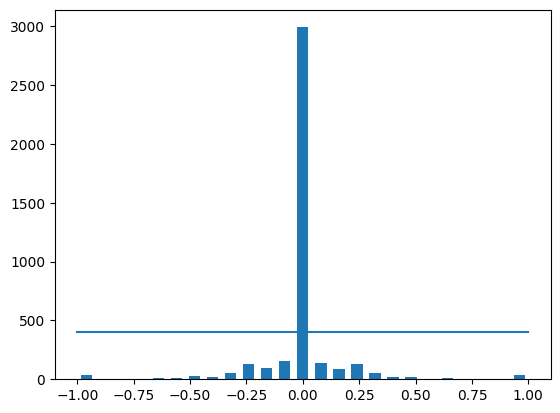

In [ ]:
num_bins = 25
samples_per_bin = 400
hist, bins = np.histogram(data['steering'], num_bins)
center = (bins[:-1]+ bins[1:]) * 0.5
plt.bar(center, hist, width=0.05)
plt.plot((np.min(data['steering']), np.max(data['steering'])), (samples_per_bin, samples_per_bin))

### 🔢 Step 6: Checking Dataset Totals
We print out the exact starting shape and length of our driving log before balancing (starting with 4,053 records).

In [ ]:
print('total data:', len(data))
print(data.shape)

total data: 4053
(4053, 7)


### ⚖️ Step 7: Balancing our Dataset (Undersampling)
To remove bias, we set a threshold of 400 maximum images per steering angle bin. This loop finds excess rows in over-represented categories (mostly straight driving) and removes them randomly to balance the dataset.

In [ ]:
# Step 1: Create an empty list to keep track of all row indices we want to remove
remove_list = []

# Step 2: Loop through each of our 25 steering angle bins
for j in range(num_bins):
    bin_indices = []

    # Go through every row in our dataset to find which bin it belongs to
    for i in range(len(data['steering'])):
        # Access the steering angle using .iloc to lookup by sequential position (0, 1, 2...)
        steering_angle = data['steering'].iloc[i]

        # Check if the steering angle falls between the lower and upper bounds of the current bin
        if steering_angle >= bins[j] and steering_angle <= bins[j+1]:
            # Store the actual DataFrame index label (e.g., 2, 7, 12 instead of just i)
            actual_index = data.index[i]
            bin_indices.append(actual_index)

    # Shuffle the indices within this bin to make the removal random and unbiased
    bin_indices = shuffle(bin_indices)

    # If the bin has more than 400 (samples_per_bin) items, keep the first 400
    # and add all the remaining excess indices to our remove list
    excess_indices = bin_indices[samples_per_bin:]
    remove_list.extend(excess_indices)

# Step 3: Print how many items we are removing
print('removed:', len(remove_list))

# Step 4: Drop those excess rows from our DataFrame
data.drop(remove_list, inplace=True)

# Step 5: Print how many balanced data points we have left
print('remaining:', len(data))

removed: 2590
remaining: 1463


### 📉 Step 8: Verifying the Balanced Dataset
We recreate our histogram to verify that the dataset is now balanced. The spike at 0.0 is capped, giving us a more uniform distribution of left, right, and straight steering examples.

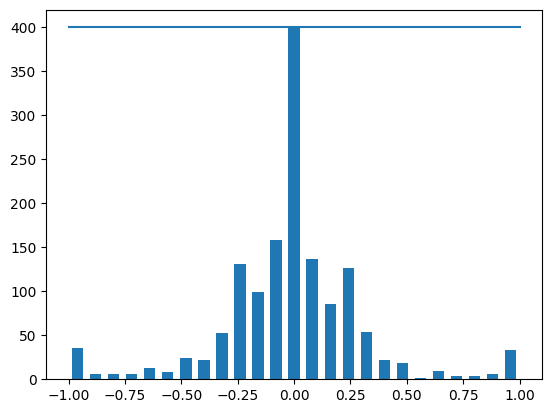

In [ ]:
hist, _ = np.histogram(data['steering'], (num_bins))
plt.bar(center, hist, width=0.05)
plt.plot((np.min(data['steering']), np.max(data['steering'])), (samples_per_bin, samples_per_bin))

### 🤳 Step 9: Defining the Multi-Camera Loading Pipeline
To increase our training samples and teach the model how to recover if it drifts, we load center, left, and right camera views. Side cameras are given an artificial steering correction offset of $\pm 0.15$.

In [ ]:
def load_img_steering(datadir, df):
  # Create empty lists to store all final image paths and steering angles
  image_paths = []
  steering_angles = []

  # Loop through every row in the DataFrame (df)
  for i in range(len(df)):
    # Get the row at the current loop index
    row_data = df.iloc[i]

    # Get the file names of the three camera images (columns 0, 1, and 2)
    center_img = row_data.iloc[0]
    left_img = row_data.iloc[1]
    right_img = row_data.iloc[2]

    # Get the base steering angle (column 3) and convert it to a float number
    base_steering = float(row_data.iloc[3])

    # 1. Add Center Image and its matching steering angle
    center_path = os.path.join(datadir, center_img.strip())
    image_paths.append(center_path)
    steering_angles.append(base_steering)

    # 2. Add Left Image and adjust steering angle (+0.15 correction to turn right back to center)
    left_path = os.path.join(datadir, left_img.strip())
    image_paths.append(left_path)
    steering_angles.append(base_steering + 0.15)

    # 3. Add Right Image and adjust steering angle (-0.15 correction to turn left back to center)
    right_path = os.path.join(datadir, right_img.strip())
    image_paths.append(right_path)
    steering_angles.append(base_steering - 0.15)

  # Convert our lists to NumPy arrays for machine learning readiness
  image_paths_array = np.asarray(image_paths)
  steering_angles_array = np.asarray(steering_angles)

  return image_paths_array, steering_angles_array

### 🛠️ Step 10: Running the Multi-Camera Image Compiler
We execute our loading function, pairing every image path (from all three camera angles) with its newly adjusted steering angle.

In [ ]:
image_paths, steerings = load_img_steering(datadir + '/IMG', data)

### ✂️ Step 11: Splitting Data into Training and Validation Sets
We divide our data into an **80% Training set** (to teach our model) and a **20% Validation set** (to test the model on unseen images).

In [ ]:
len(image_paths)

4389

In [ ]:
len(steerings)

4389

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(image_paths, steerings, test_size=0.2, random_state=6)
print('Training Samples: {}\nValid Samples: {}'.format(len(X_train), len(X_valid)))

Training Samples: 3511
Valid Samples: 878


### 🎨 Step 12: Visualizing Splitting Distributions
We plot side-by-side histograms of our train and validation splits to confirm that they both share a healthy, balanced distribution of steering angles.

Text(0.5, 1.0, 'Validation set')

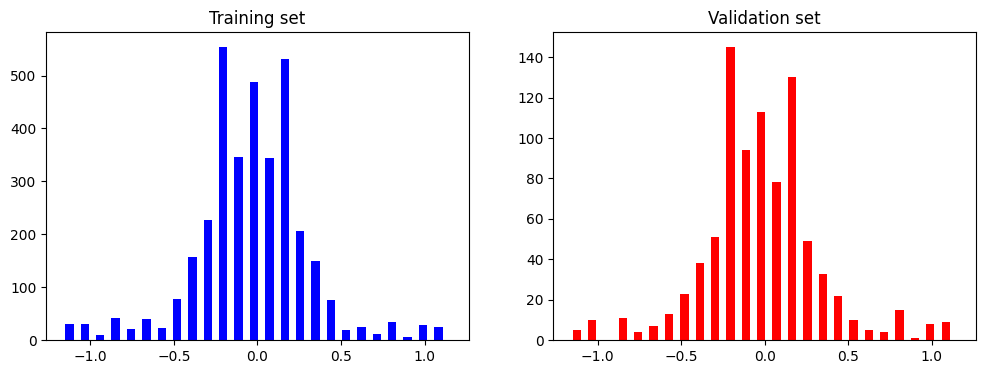

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_train, bins=num_bins, width=0.05, color='blue')
axes[0].set_title('Training set')
axes[1].hist(y_valid, bins=num_bins, width=0.05, color='red')
axes[1].set_title('Validation set')

### 🔍 Step 13: Zoom Augmentation
We define a zoom augmenter (scaling images randomly up to 1.3x) to teach the network to recognize lane details at different visual distances. We display a comparison plot to preview the effect.

Text(0.5, 1.0, 'Zoomed Image')

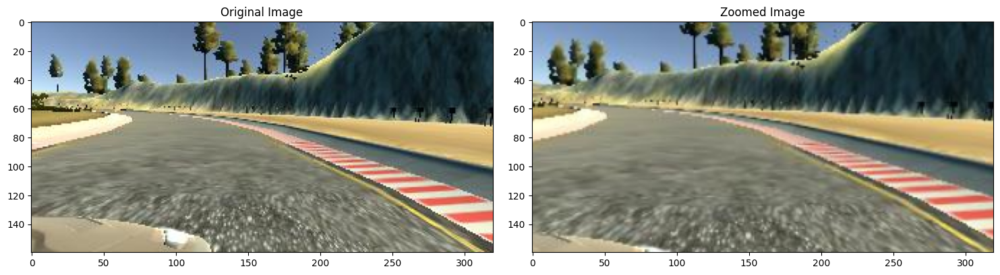

In [ ]:
# Step 1: Define a function to zoom into an image
def zoom(image):
  # Create a zoom transformation that scales the image randomly between 1.0 (no change) and 1.3 (30% zoom)
  zoom_transform = iaa.Affine(scale=(1.0, 1.3))

  # Apply this zoom effect to our input image
  zoomed_image = zoom_transform.augment_image(image)
  return zoomed_image

# Step 2: Pick a random image path from our list and load it
random_image_path = image_paths[random.randint(0, 1000)]
original_image = mpimg.imread(random_image_path)

# Step 3: Apply our zoom function to the original image
zoomed_image = zoom(original_image)

# Step 4: Create a figure with 2 side-by-side subplots to compare the results
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 10))
fig.tight_layout()  # Adjust spacing so titles and images do not overlap

# Display the original image on the left (index 0)
axes[0].imshow(original_image)
axes[0].set_title('Original Image')

# Display the zoomed image on the right (index 1)
axes[1].imshow(zoomed_image)
axes[1].set_title('Zoomed Image')

### 🗺️ Step 14: Translation (Panning) Augmentation
We implement a panning transformation that randomly shifts the image horizontally or vertically by up to 10% to simulate off-center driving viewpoints.

Text(0.5, 1.0, 'Panned Image')

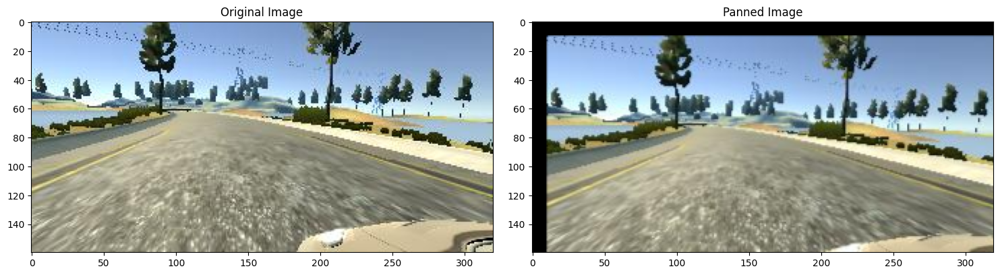

In [ ]:
# Step 1: Define a function to pan (shift/translate) an image horizontally and vertically
def pan(image):
  # Define a translation effect that randomly shifts the image:
  # - "x": horizontally between -10% (left) and +10% (right)
  # - "y": vertically between -10% (up) and +10% (down)
  pan_transform = iaa.Affine(translate_percent={"x": (-0.1, 0.1), "y": (-0.1, 0.1)})

  # Apply this panning shift to our input image
  panned_image = pan_transform.augment_image(image)
  return panned_image

# Step 2: Grab a random image from our dataset to use as a test
random_image_path = image_paths[random.randint(0, 1000)]
original_image = mpimg.imread(random_image_path)

# Step 3: Run our panning function on the loaded image
panned_image = pan(original_image)

# Step 4: Display the original and the panned image side-by-side to compare
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 10))
fig.tight_layout()  # Automatically adjusts spacing between plots

# Show the original image in the first subplot (left)
axes[0].imshow(original_image)
axes[0].set_title('Original Image')

# Show the shifted (panned) image in the second subplot (right)
axes[1].imshow(panned_image)
axes[1].set_title('Panned Image')

### 💡 Step 15: Random Brightness Augmentation
We define a function to randomly multiply image pixel intensity between 0.2 and 1.2, preparing our model to handle various track environments with shadows or intense sunlight.

Text(0.5, 1.0, 'Brightness Altered Image')

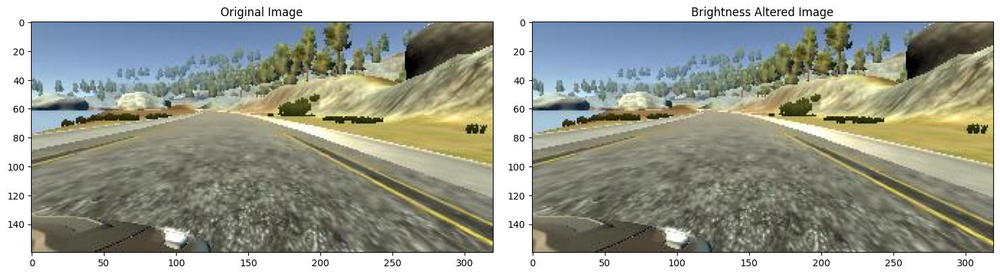

In [ ]:
# Step 1: Define a function to randomly adjust the brightness of an image
def img_random_brightness(image):
  # Multiply pixel values by a random number between 0.2 (darker) and 1.2 (brighter)
  brightness_transform = iaa.Multiply((0.2, 1.2))

  # Apply the brightness transformation to the input image
  brightness_altered_image = brightness_transform.augment_image(image)
  return brightness_altered_image

# Step 2: Grab a random image from our dataset to use as a test
random_image_path = image_paths[random.randint(0, 1000)]
original_image = mpimg.imread(random_image_path)

# Step 3: Run our random brightness function on the loaded image
brightness_altered_image = img_random_brightness(original_image)

# Step 4: Display the original and the brightness-altered image side-by-side
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 10))
fig.tight_layout()  # Adjust spacing so titles and images do not overlap

# Show the original image on the left (index 0)
axes[0].imshow(original_image)
axes[0].set_title('Original Image')

# Show the brightened/darkened image on the right (index 1)
axes[1].imshow(brightness_altered_image)
axes[1].set_title('Brightness Altered Image')

### 🔄 Step 16: Horizontal Flip Augmentation
This function mirrors the camera view horizontally and multiplies the steering angle by `-1`. This effectively turns left curves into right curves, preventing our neural network from learning a bias towards turning in one direction.

Text(0.5, 1.0, 'Flipped Image - Steering Angle: 0.25')

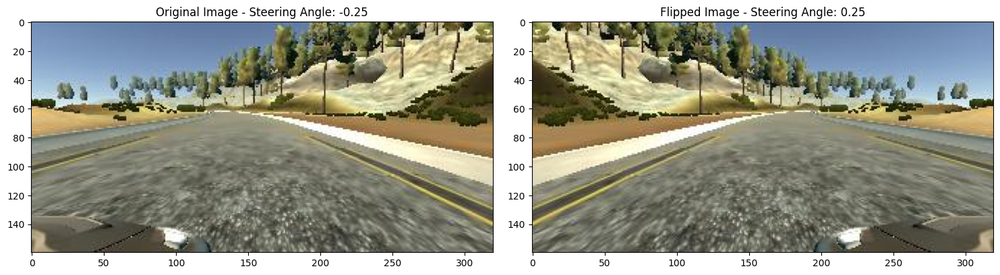

In [ ]:
# Step 1: Define a function to randomly flip an image horizontally and invert its steering angle
def img_random_flip(image, steering_angle):
  # cv2.flip with parameter 1 flips the image horizontally (left-to-right mirroring)
  flipped_image = cv2.flip(image, 1)

  # Since the image is mirrored, we must invert the steering angle (left turns become right turns, and vice-versa)
  flipped_steering_angle = -steering_angle

  return flipped_image, flipped_steering_angle

# Step 2: Grab a random image and its matching steering angle from our dataset
random_index = random.randint(0, 1000)
random_image_path = image_paths[random_index]
original_steering_angle = steerings[random_index]

# Step 3: Load the image and apply our flip function
original_image = mpimg.imread(random_image_path)
flipped_image, flipped_steering_angle = img_random_flip(original_image, original_steering_angle)

# Step 4: Display the original image and the flipped image side-by-side to compare
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 10))
fig.tight_layout()  # Automatically adjusts spacing between plots

# Display the original image on the left (index 0)
axes[0].imshow(original_image)
axes[0].set_title('Original Image - Steering Angle: ' + str(original_steering_angle))

# Display the mirrored image on the right (index 1)
axes[1].imshow(flipped_image)
axes[1].set_title('Flipped Image - Steering Angle: ' + str(flipped_steering_angle))

### 🎛️ Step 17: Master Augmentation Strategy
We define a single master function `random_augment` that rolls a virtual 50% coin-flip to decide whether to apply each of our four augmentation operations to a training sample.

In [ ]:
# Define a master function to randomly apply our different image augmentations
def random_augment(image_path, steering_angle):
  # Step 1: Load the image using its file path
  image = mpimg.imread(image_path)

  # We use 'np.random.rand() < 0.5' like flipping a coin (50% chance) for each effect.
  # This ensures our dataset gets a diverse mix of augmented images!

  # Step 2: 50% chance to shift (pan) the image
  if np.random.rand() < 0.5:
    image = pan(image)

  # Step 3: 50% chance to zoom into the image
  if np.random.rand() < 0.5:
    image = zoom(image)

  # Step 4: 50% chance to randomly change the brightness
  if np.random.rand() < 0.5:
    image = img_random_brightness(image)

  # Step 5: 50% chance to flip the image horizontally and invert the steering angle
  if np.random.rand() < 0.5:
    image, steering_angle = img_random_flip(image, steering_angle)

  # Return the newly augmented image and the updated steering angle
  return image, steering_angle

### 🖼️ Step 18: Testing the Augmentation Workflow
We run our augmentation pipeline on 10 random images from the dataset and plot them next to their original files to verify the variations.

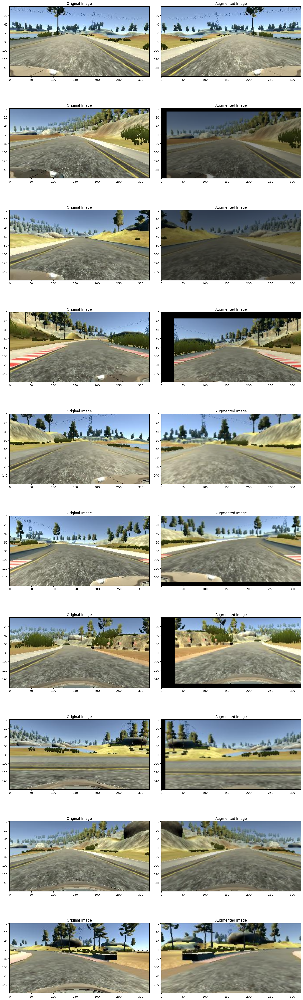

In [ ]:
# Step 1: Set up a 10-row, 2-column grid to compare original vs augmented images
num_columns = 2
num_rows = 10

fig, axes = plt.subplots(num_rows, num_columns, figsize=(15, 50))
fig.tight_layout() # Ensures our plots and titles don't overlap

# Step 2: Loop 10 times to display 10 random comparisons side-by-side
for i in range(10):
  # Pick a random index from our image path list
  random_index = random.randint(0, len(image_paths) - 1)

  # Get the path and steering angle for this random index
  random_image_path = image_paths[random_index]
  random_steering = steerings[random_index]

  # Load the original raw image
  original_image = mpimg.imread(random_image_path)

  # Get the augmented image and the updated steering angle using our master function
  augmented_image, augmented_steering = random_augment(random_image_path, random_steering)

  # Get the specific plotting boxes for this row
  original_axis = axes[i][0]
  augmented_axis = axes[i][1]

  # Plot the original image on the left column
  original_axis.imshow(original_image)
  original_axis.set_title("Original Image")

  # Plot the augmented image on the right column
  augmented_axis.imshow(augmented_image)
  augmented_axis.set_title("Augmented Image")

### ⚙️ Step 19: Defining Image Preprocessing
To optimize our input images, we:
1. Crop out non-road areas (sky/hood).
2. Convert RGB channels to the recommended YUV color space.
3. Apply a Gaussian blur to reduce noise.
4. Resize the image to $200\times66$ to match the Nvidia model input shape.
5. Normalize pixels to $[0, 1]$.

In [ ]:
def img_preprocess(img):
  # Step 1: Crop the image to remove background sky and the car's hood
  # We keep only the rows from index 60 to 135 (the actual road section)
  cropped_image = img[60:135, :, :]

  # Step 2: Convert the image from RGB to YUV color space
  # Nvidia's autonomous driving network specifically recommends YUV for road feature detection
  yuv_image = cv2.cvtColor(cropped_image, cv2.COLOR_RGB2YUV)

  # Step 3: Apply Gaussian Blur to smooth out noise and small details
  # We use a small 3x3 kernel size to keep key road line features
  blurred_image = cv2.GaussianBlur(yuv_image, (3, 3), 0)

  # Step 4: Resize the image to 200x66 pixels
  # This matches the exact input size required by the NVIDIA CNN architecture
  resized_image = cv2.resize(blurred_image, (200, 66))

  # Step 5: Normalize pixel values to be between 0.0 and 1.0 (instead of 0 to 255)
  # This helps our deep learning model train and converge much faster
  normalized_image = resized_image / 255.0

  return normalized_image

### 💻 Step 20: Preprocessing Demonstration
We run our preprocessing function on a sample image and plot the results side-by-side to visualize what the neural network actually 'sees'.

Text(0.5, 1.0, 'Preprocessed Image')

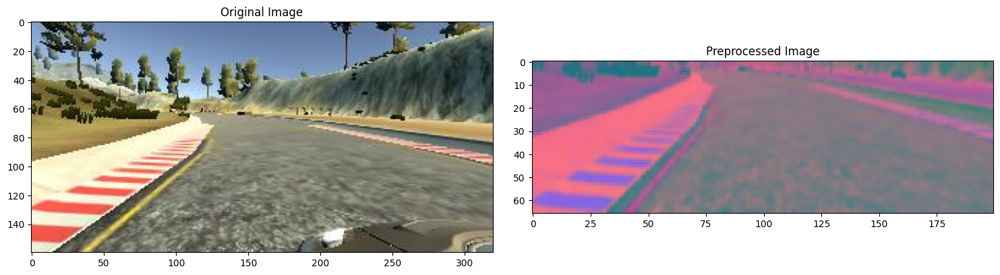

In [ ]:
# Step 1: Select a sample image path from our dataset (index 100)
sample_image_path = image_paths[100]

# Step 2: Read/load the original image using matplotlib
original_image = mpimg.imread(sample_image_path)

# Step 3: Pass our loaded image through the preprocessing function we just created
preprocessed_image = img_preprocess(original_image)

# Step 4: Create a figure with 1 row and 2 columns for a side-by-side comparison
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 10))
fig.tight_layout() # Ensures our plots and titles don't overlap

# Step 5: Assign each subplot to a descriptive variable
original_axis = axes[0]
preprocessed_axis = axes[1]

# Step 6: Plot the original image on the left subplot
original_axis.imshow(original_image)
original_axis.set_title('Original Image')

# Step 7: Plot our processed image on the right subplot
preprocessed_axis.imshow(preprocessed_image)
preprocessed_axis.set_title('Preprocessed Image')

### 🔄 Step 21: Creating the Real-time Batch Generator
Because loading thousands of high-res images directly into RAM will crash Google Colab, we write a Python generator that processes and yields images in small, RAM-friendly batches (e.g., 100 images at a time) on-the-fly during training.

In [ ]:
# Define a batch generator to feed our network with images in real-time
def batch_generator(image_paths, steering_angles, batch_size, is_training):

  # Step 1: Run an infinite loop because Keras needs the generator to continuously produce data
  while True:
    batch_images = []
    batch_steerings = []

    # Step 2: Loop to assemble a batch of the requested size (e.g., 32 or 64 images)
    for i in range(batch_size):
      # Pick a completely random image index from our dataset
      random_index = random.randint(0, len(image_paths) - 1)

      # Step 3: Decided based on training vs validation mode
      if is_training:
        # During training, load the image AND apply random data augmentations on the fly
        image, steering = random_augment(image_paths[random_index], steering_angles[random_index])
      else:
        # During validation, load the image standardly without any random alterations
        image = mpimg.imread(image_paths[random_index])
        steering = steering_angles[random_index]

      # Step 4: Preprocess the image (crop, change color space, blur, resize, normalize)
      preprocessed_image = img_preprocess(image)

      # Step 5: Append the final processed image and steering angle to our batch lists
      batch_images.append(preprocessed_image)
      batch_steerings.append(steering)

    # Step 6: Package the batch lists as NumPy arrays and yield them back to Keras
    yield (np.asarray(batch_images), np.asarray(batch_steerings))

### 🧪 Step 22: Testing our Generator
We use the python `next()` function to manually extract a single test batch of size 1 from our training and validation generators to ensure they are yielding the expected arrays.

In [ ]:
# Step 1: Request 1 training batch (batch size of 1, training mode active)
# 'next()' manually pulls the very first generated batch from our infinite loop
training_batch_images, training_batch_steerings = next(batch_generator(X_train, y_train, batch_size=1, is_training=True))

# Step 2: Request 1 validation batch (batch size of 1, training mode inactive)
validation_batch_images, validation_batch_steerings = next(batch_generator(X_valid, y_valid, batch_size=1, is_training=False))

### 📊 Step 23: Plotting Generated Batch Outputs
We display the outputs yielded by our test generator run to visually verify both the training sample and the validation sample.

Text(0.5, 1.0, 'Validation Image (Batch Gen)')

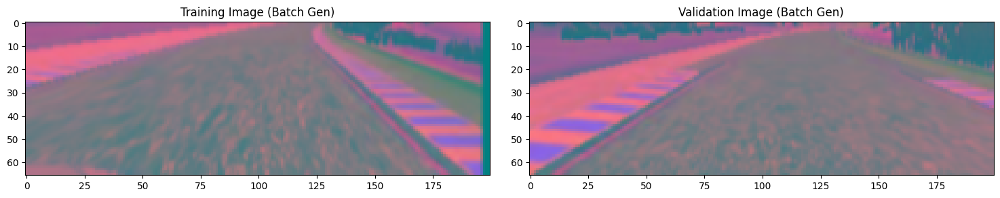

In [ ]:
# Step 1: Set up a 1-row, 2-column plot comparison
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 10))
fig.tight_layout() # Automatically adjust layout spacing

# Step 2: Show the training batch image in the first subplot (left)
# We use index 0 because our batch size is 1
axes[0].imshow(training_batch_images[0])
axes[0].set_title('Training Image (Batch Gen)')

# Step 3: Show the validation batch image in the second subplot (right)
axes[1].imshow(validation_batch_images[0])
axes[1].set_title('Validation Image (Batch Gen)')

### 🧠 Step 24: Defining the NVIDIA End-to-End Network
We build the famous NVIDIA Autonomous Driving architecture containing 5 Convolutional layers, a Flatten layer, 3 Dropout layers (50% rate) to prevent overfitting, and 4 Dense fully connected layers.

In [ ]:
def nvidia_model():
  # Step 1: Initialize a Sequential model model
  model = Sequential()

  # Step 2: Add 5 Convolutional Layers to extract visual features from the road
  # Layer 1: 24 filters, 5x5 kernel size, 2x2 stride (subsample), and ELU activation
  model.add(Conv2D(filters=24, kernel_size=(5, 5), strides=(2, 2), input_shape=(66, 200, 3), activation='elu'))

  # Layer 2: 36 filters, 5x5 kernel size, 2x2 stride
  model.add(Conv2D(filters=36, kernel_size=(5, 5), strides=(2, 2), activation='elu'))

  # Layer 3: 48 filters, 5x5 kernel size, 2x2 stride
  model.add(Conv2D(filters=48, kernel_size=(5, 5), strides=(2, 2), activation='elu'))

  # Layer 4: 64 filters, 3x3 kernel size, default 1x1 stride
  model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='elu'))

  # Layer 5: 64 filters, 3x3 kernel size, default 1x1 stride
  model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='elu'))

  # Step 3: Flatten the multi-dimensional features into a 1D vector
  model.add(Flatten())

  # Step 4: Add fully connected (Dense) layers with Dropout to prevent overfitting
  # Dense Layer 1: 100 neurons, followed by a 50% dropout rate
  model.add(Dense(units=100, activation='elu'))
  model.add(Dropout(rate=0.5))

  # Dense Layer 2: 50 neurons, followed by a 50% dropout rate
  model.add(Dense(units=50, activation='elu'))
  model.add(Dropout(rate=0.5))

  # Dense Layer 3: 10 neurons, followed by a 50% dropout rate
  model.add(Dense(units=10, activation='elu'))
  model.add(Dropout(rate=0.5))

  # Dense Layer 4: Single output node to predict the final steering angle
  model.add(Dense(units=1))

  # Step 5: Compile the model using Adam optimizer and Mean Squared Error loss
  model_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
  model.compile(loss='mse', optimizer=model_optimizer)

  return model

# Create our model and display its detailed layer-by-layer structure
model = nvidia_model()
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 31, 98, 24)     │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 47, 36)     │        21,636 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 5, 22, 48)      │        43,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 20, 64)      │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 1, 18, 64)      │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       115,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,219 (985.23 KB)

 Trainable params: 252,219 (985.23 KB)

 Non-trainable params: 0 (0.00 B)

None


### 🏋️‍♂️ Step 25: Model Training Loop
We train our model using `model.fit` over 10 epochs. The data is continuously streamed into the training loop using our training and validation generators with a batch size of 100.

In [ ]:
# Step 1: Set up the batch size
batch_size_setting = 100

# Step 2: Initialize our training and validation generators
# Training generator will apply random data augmentation (is_training=True)
# Validation generator will not apply random data augmentation (is_training=False)
train_generator = batch_generator(X_train, y_train, batch_size=batch_size_setting, is_training=True)
valid_generator = batch_generator(X_valid, y_valid, batch_size=batch_size_setting, is_training=False)

# Step 3: Train the model using the preprocessed data generators
history = model.fit(
    train_generator,
    steps_per_epoch=300,       # Number of batches to yield from training generator per epoch
    epochs=10,                 # Total iterations over the dataset
    validation_data=valid_generator,
    validation_steps=200,      # Number of batches to yield from validation generator per epoch
    verbose=1,                 # Show training progress bar and metrics
    shuffle=1                  # Shuffle data batch generation order
)

Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 134s 412ms/step - loss: 0.1177 - val_loss: 0.0808
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 117s 391ms/step - loss: 0.0936 - val_loss: 0.0725
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 115s 384ms/step - loss: 0.0873 - val_loss: 0.0696
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 114s 383ms/step - loss: 0.0858 - val_loss: 0.0657
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 116s 387ms/step - loss: 0.0813 - val_loss: 0.0623
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 120s 400ms/step - loss: 0.0805 - val_loss: 0.0631
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 109s 366ms/step - loss: 0.0788 - val_loss: 0.0613
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 109s 364ms/step - loss: 0.0782 - val_loss: 0.0611
Epoch 9/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 129s 431ms/step - loss: 0.0769 - val_loss: 0.0596
Epoch 10/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 111s 372ms/step - loss: 0.0762 - val_loss: 0.0615


### 📊 Step 26: Plotting the Loss Curve
We graph the training loss and validation loss across all 10 epochs to ensure our model converged correctly and did not overfit.

Text(0.5, 0, 'Epoch')

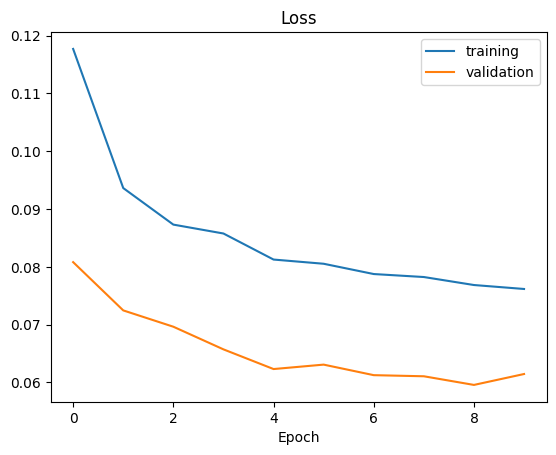

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['training', 'validation'])
plt.title('Loss')
plt.xlabel('Epoch')

### 💾 Step 27: Saving and Downloading the Trained Model
Finally, we save the completed neural network weights in the modern native Keras format (`char_model.keras`) and the legacy HDF5 format (`model.h5`). We then call Google Colab's download utility to save the file locally.

In [ ]:
# Step 1: Save the trained model
# We save in the modern, recommended '.keras' format as well as the legacy '.h5' format
model.save('char_model.keras')
model.save('model.h5')
print("Model saved successfully as both 'char_model.keras' and 'model.h5'!")

# Step 2: Download the saved model directly to your local computer
from google.colab import files
files.download('char_model.keras')

Model saved successfully as both 'char_model.keras' and 'model.h5'!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>